In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

In [2]:
df = pd.read_csv("/content/ArtificialPatientTreatment.csv")

In [3]:
df.head(10)

,patient,action,org:resource,DateTime
0,patient 0,First consult,Dr. Anna,2017-01-02 11:40:11
1,patient 0,Blood test,Lab,2017-01-02 12:47:33
2,patient 0,Physical test,Nurse Jesse,2017-01-02 12:53:50
3,patient 0,Second consult,Dr. Anna,2017-01-02 16:21:06
4,patient 0,Surgery,Dr. Charlie,2017-01-05 13:23:09
5,patient 0,Final consult,Dr. Ben,2017-01-09 08:29:28
6,patient 1,First consult,Dr. Anna,2017-01-02 12:50:35
7,patient 1,Physical test,Nurse Jesse,2017-01-02 13:59:14
8,patient 1,Blood test,Lab,2017-01-02 14:20:19
9,patient 1,X-ray scan,Team 1,2017-01-06 09:13:40


In [4]:
df.isnull().sum()

,0
patient,0
action,0
org:resource,0
DateTime,0


In [5]:
df['DateTimeChange'] = pd.to_datetime(df[' DateTime'])

In [6]:
df.head()

,patient,action,org:resource,DateTime,DateTimeChange
0,patient 0,First consult,Dr. Anna,2017-01-02 11:40:11,2017-01-02 11:40:11
1,patient 0,Blood test,Lab,2017-01-02 12:47:33,2017-01-02 12:47:33
2,patient 0,Physical test,Nurse Jesse,2017-01-02 12:53:50,2017-01-02 12:53:50
3,patient 0,Second consult,Dr. Anna,2017-01-02 16:21:06,2017-01-02 16:21:06
4,patient 0,Surgery,Dr. Charlie,2017-01-05 13:23:09,2017-01-05 13:23:09


In [7]:
df = df.sort_values(by=['patient','DateTimeChange'])

In [8]:
df.head(25)

,patient,action,org:resource,DateTime,DateTimeChange
0,patient 0,First consult,Dr. Anna,2017-01-02 11:40:11,2017-01-02 11:40:11
1,patient 0,Blood test,Lab,2017-01-02 12:47:33,2017-01-02 12:47:33
2,patient 0,Physical test,Nurse Jesse,2017-01-02 12:53:50,2017-01-02 12:53:50
3,patient 0,Second consult,Dr. Anna,2017-01-02 16:21:06,2017-01-02 16:21:06
4,patient 0,Surgery,Dr. Charlie,2017-01-05 13:23:09,2017-01-05 13:23:09
5,patient 0,Final consult,Dr. Ben,2017-01-09 08:29:28,2017-01-09 08:29:28
6,patient 1,First consult,Dr. Anna,2017-01-02 12:50:35,2017-01-02 12:50:35
7,patient 1,Physical test,Nurse Jesse,2017-01-02 13:59:14,2017-01-02 13:59:14
8,patient 1,Blood test,Lab,2017-01-02 14:20:19,2017-01-02 14:20:19
9,patient 1,X-ray scan,Team 1,2017-01-06 09:13:40,2017-01-06 09:13:40


In [11]:
df['NextActivity'] = df.groupby('patient')[' action'].shift(-1)

In [13]:
df['NextActivity'].head(20)

,NextActivity
0,Blood test
1,Physical test
2,Second consult
3,Surgery
4,Final consult
5,NaN
6,Physical test
7,Blood test
8,X-ray scan
9,Second consult


In [14]:
df['NextActivity'].isnull().sum()

np.int64(100)

In [15]:
df.isnull().sum()

,0
patient,0
action,0
org:resource,0
DateTime,0
DateTimeChange,0
NextActivity,100


In [16]:
df['NextActivity'] = df['NextActivity'].fillna(df['NextActivity'].mode()[0])

In [17]:
df.isnull().sum()

,0
patient,0
action,0
org:resource,0
DateTime,0
DateTimeChange,0
NextActivity,0


In [19]:
df['NextActivity'].head(20)

,NextActivity
0,Blood test
1,Physical test
2,Second consult
3,Surgery
4,Final consult
5,Blood test
6,Physical test
7,Blood test
8,X-ray scan
9,Second consult


In [20]:
df['sortpatient'] = df.groupby('patient')

ValueError: Length of values (100) does not match length of index (690)

In [21]:
# Group by patient to view their sequence of work activities in order
patient_activities = df.groupby('patient')[' action'].apply(list).reset_index()

# Let's display the first 10 patients and their complete sequence of activities
patient_activities.columns = ['Patient', 'ActivitySequence']
display(patient_activities.head(10))

,Patient,ActivitySequence
0,patient 0,"[ First consult, Blood test, Physical test, ..."
1,patient 1,"[ First consult, Physical test, Blood test, ..."
2,patient 10,"[ First consult, Physical test, Blood test, ..."
3,patient 11,"[ First consult, Physical test, Blood test, ..."
4,patient 12,"[ First consult, Blood test, X-ray scan, Ph..."
5,patient 13,"[ First consult, X-ray scan, Physical test, ..."
6,patient 14,"[ First consult, Blood test, X-ray scan, Ph..."
7,patient 15,"[ First consult, Physical test, Blood test, ..."
8,patient 16,"[ First consult, Physical test, Blood test, ..."
9,patient 17,"[ First consult, Physical test, X-ray scan, ..."


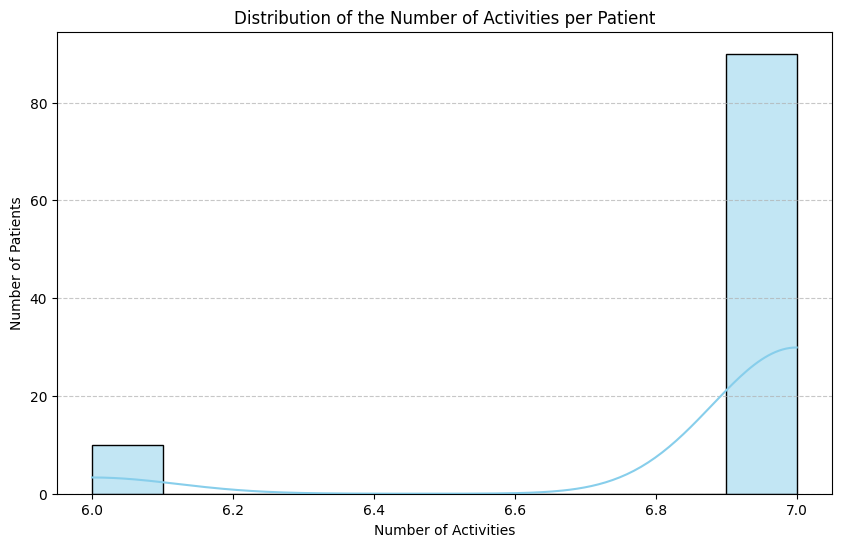

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the number of activities per patient
patient_activity_counts = df.groupby('patient').size().reset_index(name='activity_count')

# Plot the distribution of activity counts
plt.figure(figsize=(10, 6))
sns.histplot(data=patient_activity_counts, x='activity_count', bins=10, kde=True, color='skyblue')
plt.title('Distribution of the Number of Activities per Patient')
plt.xlabel('Number of Activities')
plt.ylabel('Number of Patients')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [23]:
# Ensure the data is sorted by patient and timestamp
df = df.sort_values(by=['patient', 'DateTimeChange'])

# Calculate the time difference to the next activity for each patient
df['TimeDeltaToNext'] = df.groupby('patient')['DateTimeChange'].diff(-1).abs()

# Calculate the average duration overall
average_duration = df['TimeDeltaToNext'].mean()

print(f"Average time between consecutive activities: {average_duration}")

# Also show the average time delta broken down by transition pairs (e.g., action -> NextActivity)
print("\nAverage time duration between specific activity pairs:")
transition_durations = df.groupby([' action', 'NextActivity'])['TimeDeltaToNext'].mean().reset_index()
display(transition_durations)

Average time between consecutive activities: 1 days 14:57:26.854237288

Average time duration between specific activity pairs:


,action,NextActivity,TimeDeltaToNext
0,Blood test,Physical test,0 days 12:41:31.285714285
1,Blood test,Second consult,2 days 14:49:32.454545454
2,Blood test,X-ray scan,3 days 00:22:09.281250
3,Final consult,Blood test,NaT
4,First consult,Blood test,0 days 03:32:37.125000
5,First consult,Physical test,1 days 12:43:47.787878787
6,First consult,X-ray scan,3 days 15:20:45.259259259
7,Medicine,Final consult,2 days 03:20:20.637500
8,Physical test,Blood test,0 days 01:06:01.212121212
9,Physical test,Second consult,2 days 18:27:36.944444444


In [24]:
# Calculate and clean up the transition waiting times
waiting_times = df.groupby([' action', 'NextActivity'])['TimeDeltaToNext'].mean().reset_index()
waiting_times.columns = ['Current Activity', 'Next Activity', 'Average Waiting Time']

# Drop rows where there is no transition (NaT)
waiting_times = waiting_times.dropna().sort_values(by='Average Waiting Time')

# Display the structured waiting times table
display(waiting_times)

,Current Activity,Next Activity,Average Waiting Time
14,X-ray scan,Blood test,0 days 00:43:15.851851851
8,Physical test,Blood test,0 days 01:06:01.212121212
4,First consult,Blood test,0 days 03:32:37.125000
15,X-ray scan,Physical test,0 days 06:18:54.906250
11,Second consult,Medicine,0 days 09:05:10.837500
0,Blood test,Physical test,0 days 12:41:31.285714285
5,First consult,Physical test,1 days 12:43:47.787878787
13,Surgery,Final consult,2 days 00:02:03.100000
7,Medicine,Final consult,2 days 03:20:20.637500
10,Physical test,X-ray scan,2 days 05:02:02.129032258


In [25]:
# Calculate individual step-by-step waiting times for each patient
# We filter out rows that have no subsequent activity (NaT)
individual_waiting_times = df[['patient', ' action', 'NextActivity', 'TimeDeltaToNext']].dropna().copy()
individual_waiting_times.columns = ['Patient ID', 'Current Activity', 'Next Activity', 'Waiting Time']

# Sort by Patient ID and display the first 20 individual transitions
display(individual_waiting_times.sort_values(by=['Patient ID']).head(20))

,Patient ID,Current Activity,Next Activity,Waiting Time
0,patient 0,First consult,Blood test,0 days 01:07:22
1,patient 0,Blood test,Physical test,0 days 00:06:17
2,patient 0,Physical test,Second consult,0 days 03:27:16
3,patient 0,Second consult,Surgery,2 days 21:02:03
4,patient 0,Surgery,Final consult,3 days 19:06:19
11,patient 1,Medicine,Final consult,0 days 05:01:45
9,patient 1,X-ray scan,Second consult,0 days 01:24:24
10,patient 1,Second consult,Medicine,0 days 01:09:32
7,patient 1,Physical test,Blood test,0 days 00:21:05
6,patient 1,First consult,Physical test,0 days 01:08:39


In [26]:
# Calculate the total duration of care for each patient (Max DateTime - Min DateTime)
patient_durations = df.groupby('patient')['DateTimeChange'].agg(lambda x: x.max() - x.min()).reset_index()
patient_durations.columns = ['Patient ID', 'Total Process Duration']

# Calculate the average process duration overall
average_total_duration = patient_durations['Total Process Duration'].mean()

print(f"Average total process duration per patient: {average_total_duration}")

# Display the top 10 patient durations to see the spread
display(patient_durations.head(10))

Average total process duration per patient: 9 days 13:50:56.440000


,Patient ID,Total Process Duration
0,patient 0,6 days 20:49:17
1,patient 1,4 days 03:58:46
2,patient 10,12 days 21:06:02
3,patient 11,13 days 20:37:53
4,patient 12,6 days 23:35:19
5,patient 13,8 days 00:40:34
6,patient 14,7 days 21:38:35
7,patient 15,7 days 21:55:01
8,patient 16,11 days 16:08:38
9,patient 17,13 days 00:44:02


/tmp/ipykernel_895/191171290.py:21: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = plt.cm.get_cmap('tab10', len(unique_activities))


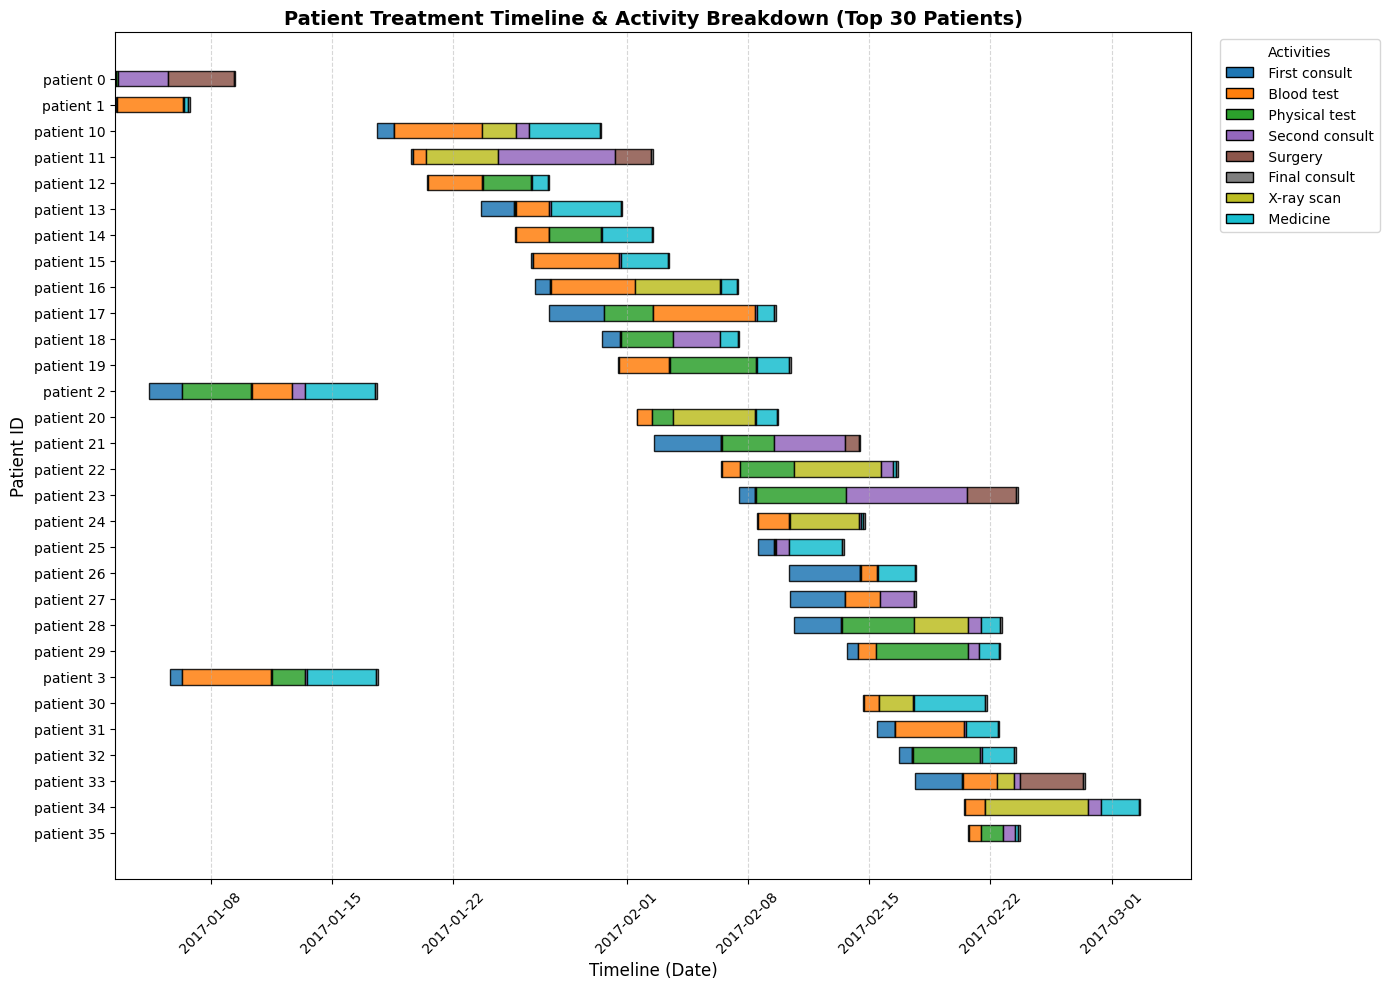

In [27]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
import numpy as np

# Ensure clean, chronological sorting
df_sorted = df.sort_values(by=['patient', 'DateTimeChange']).copy()

# Calculate the end time of each activity using the next activity's start time.
# For the final activity of a patient, we will represent it as a point or give it a tiny nominal duration (e.g., 2 hours) so it displays.
df_sorted['EndTime'] = df_sorted.groupby('patient')['DateTimeChange'].shift(-1)
df_sorted['EndTime'] = df_sorted['EndTime'].fillna(df_sorted['DateTimeChange'] + pd.Timedelta(hours=2))

# We will plot a subset of patients if there are too many, to keep the chart legible.
# Let's visualize the first 30 patients.
unique_patients = df_sorted['patient'].unique()[:30]
df_subset = df_sorted[df_sorted['patient'].isin(unique_patients)].copy()

# Map unique activities to distinct colors
unique_activities = df_sorted[' action'].unique()
colors = plt.cm.get_cmap('tab10', len(unique_activities))
activity_colors = {activity: colors(i) for i, activity in enumerate(unique_activities)}

fig, ax = plt.subplots(figsize=(14, 10))

# We will plot horizontal bars for each activity segment
for i, patient in enumerate(unique_patients):
    patient_data = df_subset[df_subset['patient'] == patient]
    for _, row in patient_data.iterrows():
        start = mdates.date2num(row['DateTimeChange'])
        end = mdates.date2num(row['EndTime'])
        duration = end - start

        ax.barh(y=i, width=duration, left=start,
                color=activity_colors[row[' action']],
                edgecolor='black', height=0.6, alpha=0.85)

# Formatting axes
ax.set_yticks(range(len(unique_patients)))
ax.set_yticklabels(unique_patients)
ax.invert_yaxis()  # Patient 0 at the top

# Format date on X-axis
ax.xaxis_date()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
plt.xticks(rotation=45)

# Create a legend
handles = [plt.Rectangle((0,0),1,1, color=activity_colors[act], ec='k') for act in unique_activities]
ax.legend(handles, unique_activities, title="Activities", bbox_to_anchor=(1.02, 1), loc='upper left')

ax.set_title('Patient Treatment Timeline & Activity Breakdown (Top 30 Patients)', fontsize=14, fontweight='bold')
ax.set_xlabel('Timeline (Date)', fontsize=12)
ax.set_ylabel('Patient ID', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()